# Tugas UTS: Linear Regression & Logistic Regression
**Mata Kuliah:** Machine Learning

Tugas ini menguji pemahaman Anda tentang materi **Simple Regression** (`simple_regression/regression_1.ipynb`) dan **Simple Classification** (`simple_classification/classification_1.ipynb`). Anda akan menerapkan algoritma yang sama pada **dataset baru**, lalu mengembangkannya dengan evaluasi dan eksperimen tambahan.

**Identitas Mahasiswa**
- Nama  : Bagas Arief Pratama
- NIM   : 241011400548
- Kelas : Reg B

## 📌 Ketentuan Pengerjaan

1. Kerjakan semua soal di notebook ini pada sel kode / sel markdown yang telah disediakan.

2. **Model dan metrik evaluasi wajib diimplementasikan sendiri** dengan NumPy, seperti pada materi (`train_test_split`, `LinearRegression`, `LinearRegressionGD`, `LogisticRegression`, `accuracy_score`, `confusion_matrix`). Anda boleh menyalin implementasi dari materi.
   - Library yang boleh dipakai: `numpy`, `pandas`, `matplotlib`.
   - **scikit-learn tidak boleh dipakai untuk model dan metrik**, kecuali pada soal bonus untuk membandingkan hasil.

3. `random_state` = **2 digit terakhir NIM Anda** (contoh: NIM `...0347` → `random_state=47`; jika `00`, gunakan `100`). Karena itu, setiap mahasiswa akan mendapat hasil angka yang berbeda.

4. Setiap soal yang meminta **penjelasan/analisis** dijawab dengan kalimat Anda sendiri pada sel Markdown, dan harus merujuk ke angka/grafik hasil Anda.

5. Notebook harus sudah dijalankan (**Run All**) sehingga semua output dan grafik terlihat saat dibuka di GitHub.

## 📁 Dataset

Dataset disediakan di folder ini:

| File | Kolom | Keterangan |
|---|---|---|
| `Ads_Data.csv` | `BiayaIklan`, `Penjualan` | Biaya iklan per bulan (juta Rp) dan penjualan per bulan (juta Rp), 40 data |
| `Email_Data.csv` | `JumlahLink`, `KataPromo`, `Spam` | Jumlah link dan jumlah kata promosi dalam sebuah email, serta label Spam (1) / Bukan Spam (0), 60 data |

### 📤 Cara Pengumpulan

1. Buat **repositori baru** di akun GitHub Anda masing-masing dengan nama: `uts-machine-learning-<NIM>` (contoh: `uts-machine-learning-2023081047`).
2. Atur repositori menjadi **Public**.
3. Struktur repositori minimal:
   - `README.md` : Nama, NIM, Kelas, dan ringkasan hasil ($R^2$, akurasi, dll)
   - `tugas_UTS.ipynb` : notebook ini, sudah dijalankan lengkap dengan output
   - `Ads_Data.csv`
   - `Email_Data.csv`

4. Kumpulkan **link repositori GitHub** di halaman **UTS pada Mentari**.
5. Batas waktu pengumpulan (hari terakhir periode UTS):
   - **Reg B**: Jumat, 23 Oktober 2026, pukul 23:59 WIB
   - **Reg C**: Sabtu, 24 Oktober 2026, pukul 23:59 WIB

> ⚠️ Yang dinilai adalah **commit terakhir sebelum batas waktu**. Commit setelah batas waktu tidak akan dinilai. Pastikan link yang dikumpulkan bisa dibuka (repositori tidak *private*).

---

### 📊 Penilaian

| Bagian | Bobot |
| :--- | :---: |
| Bagian A – Linear Regression | 35% |
| Bagian B – Logistic Regression | 40% |
| Bagian C – Pemahaman Konsep | 15% |
| Kerapihan repositori, README, dan notebook (output lengkap, kode rapi & diberi komentar) | 10% |
| Bonus – Perbandingan dengan scikit-learn | +5 |

In [1]:
# import Library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RANDOM_STATE = 48    # Sesuai 2 digit terakhir NIM (241011400548)
print(f"RANDOM_STATE diset ke: {RANDOM_STATE}")

RANDOM_STATE diset ke: 48


In [2]:
def train_test_split(X, y, test_size=0.2, random_state=None):
    if random_state is not None:
        np.random.seed(random_state)
    
    n_samples = len(X)
    shuffled_indices = np.random.permutation(n_samples)
    test_set_size = int(n_samples * test_size)
    
    test_indices = shuffled_indices[:test_set_size]
    train_indices = shuffled_indices[test_set_size:]
    
    if isinstance(X, pd.DataFrame) or isinstance(X, pd.Series):
        X_train, X_test = X.iloc[train_indices], X.iloc[test_indices]
    else:
        X_train, X_test = X[train_indices], X[test_indices]
        
    if isinstance(y, pd.DataFrame) or isinstance(y, pd.Series):
        y_train, y_test = y.iloc[train_indices], y.iloc[test_indices]
    else:
        y_train, y_test = y[train_indices], y[test_indices]
        
    return X_train, X_test, y_train, y_test

---
# Bagian A – Linear Regression (35%)

Sebuah toko online ingin mengetahui pengaruh **biaya iklan** terhadap **penjualan** setiap bulan. Gunakan dataset `Ads_Data.csv`.

### Soal A1 – Load & Visualisasi Data
1. Baca `Ads_Data.csv` menggunakan pandas dan tampilkan 5 data pertama serta jumlah baris datanya.
2. Pisahkan `X` (`BiayaIklan`) dan `y` (`Penjualan`). Pastikan `X` berbentuk 2 dimensi `(n, 1)`.
3. Buat *scatter plot* `BiayaIklan` vs `Penjualan` (lengkap dengan judul dan label sumbu).

5 Data Pertama Ads_Data.csv:
   BiayaIklan  Penjualan
0         0.8       34.3
1         0.9       38.8
2         1.0       33.2
3         1.3       36.0
4         1.7       51.3

Jumlah baris data: 40
Shape X: (40, 1) | Shape y: (40,)
Korelasi BiayaIklan-Penjualan: 0.9712


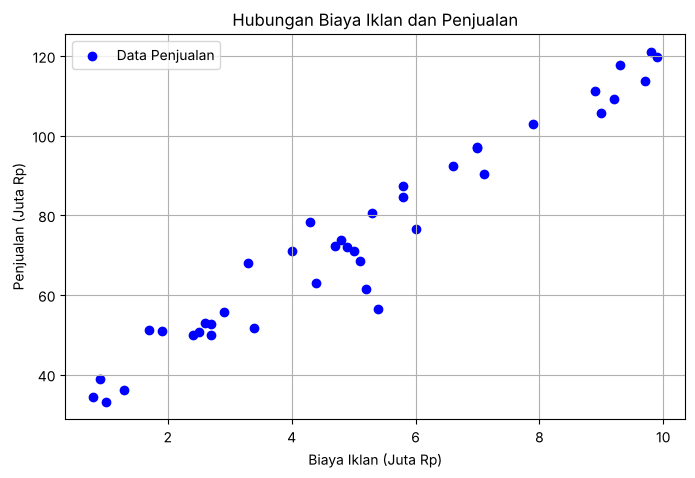

In [3]:
# Jawaban A1
df_ads = pd.read_csv('Ads_Data.csv')
print("5 Data Pertama Ads_Data.csv:")
print(df_ads.head())
print(f"\nJumlah baris data: {len(df_ads)}")

X_ads = df_ads[['BiayaIklan']].values
y_ads = df_ads['Penjualan'].values
print(f"Shape X: {X_ads.shape} | Shape y: {y_ads.shape}")
print(f"Korelasi BiayaIklan-Penjualan: {np.corrcoef(X_ads.ravel(), y_ads)[0, 1]:.4f}")

plt.figure(figsize=(8, 5))
plt.scatter(X_ads, y_ads, color='blue', label='Data Penjualan')
plt.title('Hubungan Biaya Iklan dan Penjualan')
plt.xlabel('Biaya Iklan (Juta Rp)')
plt.ylabel('Penjualan (Juta Rp)')
plt.grid(True)
plt.legend()
plt.show()

**Jawaban A1:**
Dataset `Ads_Data.csv` berisi 40 baris dengan dua kolom, yaitu `BiayaIklan` dan `Penjualan` (keduanya dalam juta Rp). `X` dibentuk dari `df_ads[['BiayaIklan']].values` sehingga berbentuk 2 dimensi `(40, 1)`, sedangkan `y` berbentuk `(40,)`.

Pada scatter plot, titik-titik membentuk pola yang naik hampir lurus: biaya iklan sekitar 0.8 juta menghasilkan penjualan sekitar 34 juta, sedangkan biaya iklan sekitar 9.9 juta menghasilkan penjualan sekitar 120 juta. Nilai korelasi sebesar **0.9712** menunjukkan hubungan positif yang sangat kuat dan cukup linear, sehingga Linear Regression layak dipakai pada data ini. Sebaran titik sedikit melebar pada biaya iklan 4-6 juta (penjualan berkisar 56-87 juta), tetapi tren keseluruhan tetap naik.

### Soal A2 – Split Data
Bagi data menjadi data training dan testing dengan `test_size=0.2` dan `random_state=RANDOM_STATE`. Tampilkan *shape* dari `X_train`, `X_test`, `y_train`, `y_test`.

In [4]:
# Jawaban A2
X_train_a, X_test_a, y_train_a, y_test_a = train_test_split(X_ads, y_ads, test_size=0.2, random_state=RANDOM_STATE)

print("Shape X_train:", X_train_a.shape)
print("Shape X_test :", X_test_a.shape)
print("Shape y_train:", y_train_a.shape)
print("Shape y_test :", y_test_a.shape)

Shape X_train: (32, 1)
Shape X_test : (8, 1)
Shape y_train: (32,)
Shape y_test : (8,)


**Jawaban A2:**
Dengan `test_size=0.2` dan `random_state=48`, 40 data terbagi menjadi **32 data training** dan **8 data testing**: `X_train` `(32, 1)`, `X_test` `(8, 1)`, `y_train` `(32,)`, dan `y_test` `(8,)`. Pembagian dilakukan dengan mengacak indeks memakai seed 48, sehingga hasilnya selalu sama setiap notebook dijalankan ulang. Karena data testing hanya 8 titik, nilai metrik pada data testing cukup sensitif terhadap titik mana yang kebetulan terambil.

### Soal A3 – Training dengan Normal Equation
1. Latih model `LinearRegression` (normal equation, seperti di materi) menggunakan data training.
2. Tampilkan nilai **intercept** ($b$) dan **koefisien** ($m$), lalu tuliskan persamaan garis regresinya: $\hat{y} = b + mX$.
3. **Interpretasikan** arti nilai $m$ dalam konteks kasus ini.

In [5]:
# Jawaban A3
class LinearRegressionNormalEq:
    def fit(self, X, y):
        X_b = np.c_[np.ones((X.shape[0], 1)), X]
        theta = np.linalg.inv(X_b.T.dot(X_b)).dot(X_b.T).dot(y)
        self.intercept_ = theta[0]
        self.coef_ = theta[1:]
        
    def predict(self, X):
        return self.intercept_ + np.dot(X, self.coef_)

model_a3 = LinearRegressionNormalEq()
model_a3.fit(X_train_a, y_train_a)

print(f"Intercept (b) : {model_a3.intercept_:.4f}")
print(f"Koefisien (m) : {model_a3.coef_[0]:.4f}")
print(f"Persamaan     : y_hat = {model_a3.intercept_:.4f} + {model_a3.coef_[0]:.4f} * BiayaIklan")

Intercept (b) : 29.1879
Koefisien (m) : 8.9897
Persamaan     : y_hat = 29.1879 + 8.9897 * BiayaIklan


**Jawaban A3 (interpretasi):**
Model normal equation menghasilkan intercept $b = 29.1879$ dan koefisien $m = 8.9897$, sehingga persamaan garis regresinya adalah $\hat{y} = 29.1879 + 8.9897 \cdot \text{BiayaIklan}$.

Nilai $m = 8.9897$ berarti setiap kenaikan biaya iklan sebesar Rp1 juta per bulan diperkirakan menaikkan penjualan sekitar Rp8.99 juta per bulan. Tanda positif menunjukkan hubungan searah: semakin besar biaya iklan, semakin tinggi penjualan. Nilai intercept $b = 29.1879$ adalah estimasi penjualan ketika biaya iklan 0, tetapi data terkecil berada di biaya iklan 0.8 juta, sehingga nilai ini lebih tepat dipahami sebagai titik awal garis daripada prediksi yang pasti.

### Soal A4 – Evaluasi Model
Implementasikan fungsi MAE, MSE, RMSE, dan R^2 menggunakan NumPy, lalu hitung pada data training dan testing.

In [6]:
# Jawaban A4
def mae(y_true, y_pred):
    return np.mean(np.abs(y_true - y_pred))

def mse(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

def rmse(y_true, y_pred):
    return np.sqrt(mse(y_true, y_pred))

def r2_score(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    return 1 - (ss_res / ss_tot)

y_pred_train_a = model_a3.predict(X_train_a)
y_pred_test_a = model_a3.predict(X_test_a)

eval_a = pd.DataFrame({
    'Metric': ['MAE', 'MSE', 'RMSE', 'R2 Score'],
    'Train': [mae(y_train_a, y_pred_train_a), mse(y_train_a, y_pred_train_a), rmse(y_train_a, y_pred_train_a), r2_score(y_train_a, y_pred_train_a)],
    'Test': [mae(y_test_a, y_pred_test_a), mse(y_test_a, y_pred_test_a), rmse(y_test_a, y_pred_test_a), r2_score(y_test_a, y_pred_test_a)]
})

print(eval_a.to_string(index=False))

  Metric     Train      Test
     MAE  4.088272  6.296629
     MSE 27.097219 72.947783
    RMSE  5.205499  8.540947
R2 Score  0.954845  0.902898


**Jawaban A4 (analisis):**

| Metrik | Training | Testing |
|---|---|---|
| MAE | 4.0883 | 6.2966 |
| MSE | 27.0972 | 72.9478 |
| RMSE | 5.2055 | 8.5409 |
| $R^2$ | 0.9548 | 0.9029 |

Nilai $R^2$ pada data testing sebesar **0.9029** artinya model menjelaskan sekitar 90.3% variasi penjualan pada data yang belum pernah dilihat (pada data training 95.5%). RMSE testing sebesar 8.54 berarti prediksi rata-rata meleset sekitar Rp8.5 juta dari penjualan sebenarnya, sedangkan rentang penjualan pada data adalah 33.2-121.1 juta. RMSE (8.54) yang lebih besar dari MAE (6.30) menandakan ada beberapa titik testing dengan kesalahan yang lebih besar dari yang lain.

Error pada data testing memang lebih besar daripada training (RMSE 8.54 dibanding 5.21), hal yang wajar karena model dilatih pada data training dan data testing hanya terdiri dari 8 titik. Selisih $R^2$ antara training dan testing hanya sekitar 0.05, sehingga tidak ada tanda overfitting yang serius dan model masih bisa digeneralisasi dengan baik.

### Soal A5 – Gradient Descent & Learning Rate
Latih model `LinearRegressionGD` dengan 3 nilai learning rate (0.001, 0.02, dan 0.1) serta bandingkan hasil grafiknya.

LR 0.001 -> Intercept: 26.2542, Coef: 9.4551, Loss akhir: 29.0595
LR 0.02 -> Intercept: 29.1879, Coef: 8.9897, Loss akhir: 27.0972
LR 0.1 -> Intercept: nan, Coef: nan, Loss akhir: nan


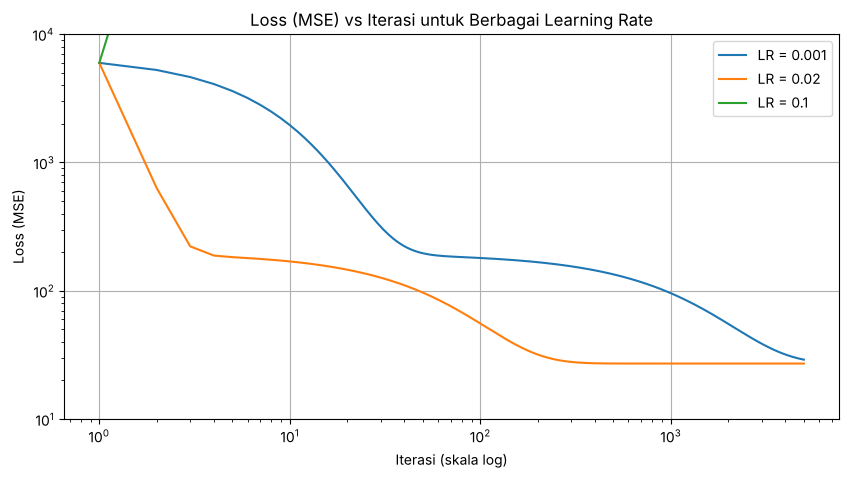

In [7]:
# Jawaban A5
class LinearRegressionGD:
    def __init__(self, lr=0.01, n_iterations=5000):
        self.lr = lr
        self.n_iterations = n_iterations
        
    def fit(self, X, y):
        m, n = X.shape
        self.w = np.zeros(n)
        self.b = 0.0
        self.loss_history = []
        
        for _ in range(self.n_iterations):
            y_pred = np.dot(X, self.w) + self.b
            loss = np.mean((y_pred - y) ** 2)
            self.loss_history.append(loss)
            
            dw = (2/m) * np.dot(X.T, (y_pred - y))
            db = (2/m) * np.sum(y_pred - y)
            
            self.w -= self.lr * dw
            self.b -= self.lr * db

learning_rates = [0.001, 0.02, 0.1]
plt.figure(figsize=(10, 5))

for lr in learning_rates:
    model = LinearRegressionGD(lr=lr, n_iterations=5000)
    model.fit(X_train_a, y_train_a)
    print(f"LR {lr} -> Intercept: {model.b:.4f}, Coef: {model.w[0]:.4f}, Loss akhir: {model.loss_history[-1]:.4f}")
    plt.plot(range(1, len(model.loss_history) + 1), model.loss_history, label=f'LR = {lr}')

plt.title('Loss (MSE) vs Iterasi untuk Berbagai Learning Rate')
plt.xlabel('Iterasi (skala log)')
plt.ylabel('Loss (MSE)')
plt.xscale('log')   # iterasi awal terlihat jelas
plt.yscale('log')
plt.ylim(10, 1e4)   # batasi sumbu y: loss LR 0.1 meledak hingga overflow (NaN)
plt.legend()
plt.grid(True)
plt.show()

**Jawaban A5 (analisis):**

| Learning rate | Intercept | Koefisien | Loss akhir (5000 iterasi) | Kesimpulan |
|---|---|---|---|---|
| 0.001 | 26.2542 | 9.4551 | 29.0595 | Terlalu lambat, belum konvergen |
| 0.02 | 29.1879 | 8.9897 | 27.0972 | Konvergen, stabil |
| 0.1 | NaN | NaN | NaN | Divergen (overflow) |

- **Learning rate 0.001** terlalu kecil. Loss turun sangat lambat (masih 95.83 pada iterasi ke-1000) dan kurvanya masih menurun saat iterasi berakhir: loss 29.0595 pada iterasi ke-5000, masih di atas 27.0972. Akibatnya parameter (26.2542 dan 9.4551) belum sampai ke solusi normal equation (29.1879 dan 8.9897); dibutuhkan iterasi lebih banyak.
- **Learning rate 0.02** paling baik. Loss sudah mendekati nilai akhirnya pada sekitar iterasi ke-360 dan berhenti di 27.0972, sama dengan MSE training pada normal equation. Intercept 29.1879 dan koefisien 8.9897 identik dengan hasil normal equation pada soal A3.
- **Learning rate 0.1** terlalu besar. Setiap langkah melompati titik minimum sehingga loss justru membesar: sudah mencapai sekitar $8 \times 10^{16}$ pada iterasi ke-10, lalu overflow menjadi NaN. Pada grafik (sumbu x dan y berskala log), kurva LR = 0.1 langsung melonjak keluar dari batas atas sumbu y dalam beberapa iterasi pertama lalu menghilang karena nilainya NaN, dan parameter yang dihasilkan tidak bisa dipakai.

Kesimpulannya, learning rate harus dipilih di antara terlalu kecil (lambat) dan terlalu besar (divergen), dan gradient descent dengan learning rate yang tepat akan mencapai solusi yang sama dengan normal equation.

### Soal A6 – Visualisasi & Prediksi
Buat scatter plot data testing beserta garis regresi, lalu lakukan prediksi untuk biaya iklan 4.5 juta, 7 juta, dan 12 juta.

Prediksi penjualan untuk Biaya Iklan 4.5 Juta Rp = 69.64 Juta Rp
Prediksi penjualan untuk Biaya Iklan 7.0 Juta Rp = 92.12 Juta Rp
Prediksi penjualan untuk Biaya Iklan 12.0 Juta Rp = 137.06 Juta Rp


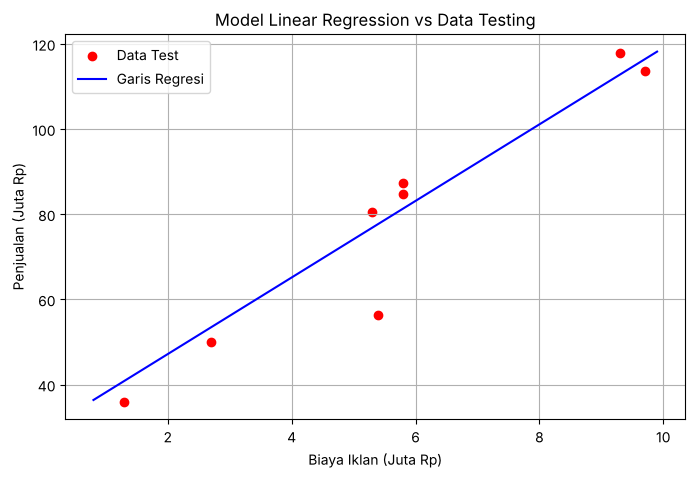

In [8]:
# Jawaban A6
plt.figure(figsize=(8, 5))
plt.scatter(X_test_a, y_test_a, color='red', label='Data Test')
x_line = np.linspace(X_ads.min(), X_ads.max(), 100).reshape(-1, 1)
y_line = model_a3.predict(x_line)
plt.plot(x_line, y_line, color='blue', label='Garis Regresi')
plt.title('Model Linear Regression vs Data Testing')
plt.xlabel('Biaya Iklan (Juta Rp)')
plt.ylabel('Penjualan (Juta Rp)')
plt.legend()
plt.grid(True)
plt.show()

new_costs = np.array([[4.5], [7.0], [12.0]])
predictions = model_a3.predict(new_costs)

for cost, pred in zip(new_costs, predictions):
    print(f"Prediksi penjualan untuk Biaya Iklan {cost[0]} Juta Rp = {pred:.2f} Juta Rp")

**Jawaban A6 (analisis):**

| Biaya iklan | Prediksi penjualan |
|---|---|
| 4.5 juta | 69.64 juta |
| 7.0 juta | 92.12 juta |
| 12.0 juta | 137.06 juta |

Biaya iklan 4.5 juta dan 7 juta berada di dalam rentang data latih (0.8-9.9 juta), sehingga prediksinya berupa interpolasi dan cukup dapat dipercaya. Biaya iklan 12 juta berada di luar rentang data, jadi prediksinya merupakan **ekstrapolasi**. Hasil 137.06 juta bahkan melebihi penjualan tertinggi yang pernah tercatat (121.1 juta). Model mengasumsikan hubungan tetap linear di luar rentang data, padahal efek iklan bisa saja mulai jenuh pada biaya yang lebih besar, sehingga prediksi ini memiliki tingkat kepercayaan yang lebih rendah.

---
# Bagian B – Logistic Regression (40%)

Sebuah layanan email ingin membuat filter **spam** berdasarkan `JumlahLink` dan `KataPromo`. Gunakan dataset `Email_Data.csv`.

### Soal B1 – Load & Visualisasi Data
Baca `Email_Data.csv`, tampilkan 5 data pertama, hitung jumlah spam/bukan spam, dan buat scatter plot.

5 Data Pertama Email_Data.csv:
   JumlahLink  KataPromo  Spam
0           0          0     0
1           2          4     0
2           6          7     1
3          10          8     1
4           8          7     1

Jumlah email Spam dan Bukan Spam:
Spam
0    35
1    25
Name: count, dtype: int64


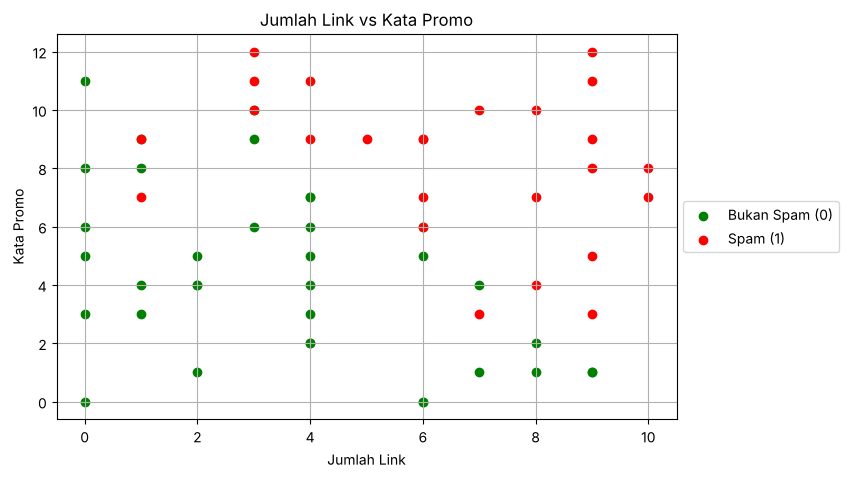

In [9]:
# Jawaban B1
df_email = pd.read_csv('Email_Data.csv')
print("5 Data Pertama Email_Data.csv:")
print(df_email.head())
print("\nJumlah email Spam dan Bukan Spam:")
print(df_email['Spam'].value_counts())

X_email = df_email[['JumlahLink', 'KataPromo']].values
y_email = df_email['Spam'].values

plt.figure(figsize=(8, 5))
plt.scatter(X_email[y_email==0][:, 0], X_email[y_email==0][:, 1], color='green', label='Bukan Spam (0)')
plt.scatter(X_email[y_email==1][:, 0], X_email[y_email==1][:, 1], color='red', label='Spam (1)')
plt.title('Jumlah Link vs Kata Promo')
plt.xlabel('Jumlah Link')
plt.ylabel('Kata Promo')
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.grid(True)
plt.show()

**Jawaban B1:**
Dataset `Email_Data.csv` berisi 60 email, terdiri dari **35 bukan spam (58.3%)** dan **25 spam (41.7%)**. Proporsinya agak tidak seimbang tetapi belum parah.

Pada scatter plot, email spam (merah) umumnya berada di kanan atas, yaitu email dengan jumlah link dan kata promosi yang sama-sama tinggi. Email bukan spam (hijau) lebih banyak di kiri bawah. Kedua fitur saling melengkapi: ada email dengan banyak link tetapi sedikit kata promosi yang bukan spam (misalnya 9 link dengan 1 kata promosi), dan ada email dengan sedikit link tetapi banyak kata promosi yang spam. Karena itu batas kelasnya berupa garis miring, bukan garis tegak atau datar.

Sebagian titik juga bertumpuk: kombinasi (1 link, 9 kata promosi), (3, 10), dan (6, 6) masing-masing muncul dengan label yang berbeda. Artinya kelas ini tidak bisa dipisahkan sempurna oleh model apa pun yang hanya memakai dua fitur ini, sehingga akurasi 100% tidak realistis.

### Soal B2 – Split Data & Training
Latih model `LogisticRegression` menggunakan Gradient Descent dengan learning_rate=0.1 dan n_iterations=10000.

Intercept (b)  : -10.4244
Koefisien (m1) : 0.9246
Koefisien (m2) : 0.8837


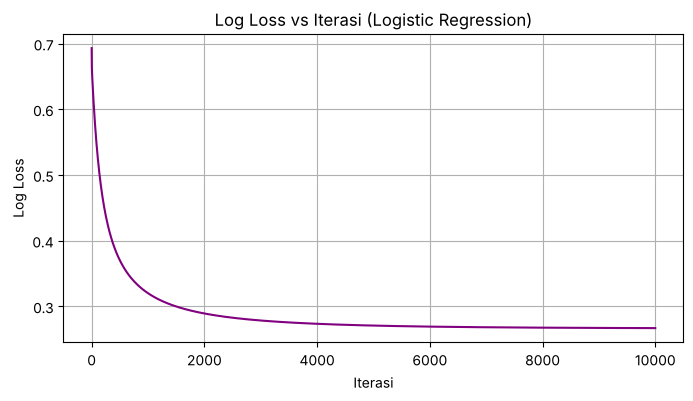

In [10]:
# Jawaban B2
X_train_b, X_test_b, y_train_b, y_test_b = train_test_split(X_email, y_email, test_size=0.25, random_state=RANDOM_STATE)

class LogisticRegressionGD:
    def __init__(self, lr=0.1, n_iterations=10000):
        self.lr = lr
        self.n_iterations = n_iterations
        
    def sigmoid(self, z):
        return 1 / (1 + np.exp(-np.clip(z, -250, 250)))
        
    def fit(self, X, y):
        m, n = X.shape
        self.w = np.zeros(n)
        self.b = 0.0
        self.loss_history = []
        
        for _ in range(self.n_iterations):
            linear_model = np.dot(X, self.w) + self.b
            y_predicted = self.sigmoid(linear_model)
            
            epsilon = 1e-15
            y_pred_clipped = np.clip(y_predicted, epsilon, 1 - epsilon)
            loss = -np.mean(y * np.log(y_pred_clipped) + (1 - y) * np.log(1 - y_pred_clipped))
            self.loss_history.append(loss)
            
            dw = (1/m) * np.dot(X.T, (y_predicted - y))
            db = (1/m) * np.sum(y_predicted - y)
            
            self.w -= self.lr * dw
            self.b -= self.lr * db
            
    def predict_proba(self, X):
        return self.sigmoid(np.dot(X, self.w) + self.b)
        
    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

model_b = LogisticRegressionGD(lr=0.1, n_iterations=10000)
model_b.fit(X_train_b, y_train_b)

print(f"Intercept (b)  : {model_b.b:.4f}")
print(f"Koefisien (m1) : {model_b.w[0]:.4f}")
print(f"Koefisien (m2) : {model_b.w[1]:.4f}")

plt.figure(figsize=(8, 4))
plt.plot(range(len(model_b.loss_history)), model_b.loss_history, color='purple')
plt.title('Log Loss vs Iterasi (Logistic Regression)')
plt.xlabel('Iterasi')
plt.ylabel('Log Loss')
plt.grid(True)
plt.show()

**Jawaban B2:**
Dengan `test_size=0.25` dan `random_state=48`, 60 data terbagi menjadi 45 data training dan 15 data testing. Hasil training Gradient Descent (learning rate 0.1, 10000 iterasi): intercept $b = -10.4244$, $m_1 = 0.9246$ (JumlahLink), dan $m_2 = 0.8837$ (KataPromo).

- Kedua koefisien **positif**: semakin banyak link atau kata promosi, semakin besar peluang email dikategorikan spam.
- Satu tambahan link mengalikan odds spam sekitar $e^{0.9246} = 2.52$ kali, dan satu tambahan kata promosi mengalikannya sekitar $e^{0.8837} = 2.42$ kali (dengan fitur lain tetap). Kedua fitur berpengaruh hampir sama besar, dan skalanya sama-sama 0-12 sehingga koefisiennya bisa dibandingkan langsung.
- Intercept yang sangat negatif ($-10.42$) berarti email tanpa link dan tanpa kata promosi punya probabilitas spam hampir 0.

Pada grafik log loss, nilai awalnya 0.6931 (sama dengan $\ln 2$ karena parameter dimulai dari nol), turun menjadi 0.5351 pada iterasi ke-100, 0.3201 pada iterasi ke-1000, 0.2707 pada iterasi ke-5000, dan 0.2669 pada iterasi ke-10000. Kurva turun terus dan melandai, jadi training sudah konvergen (perubahan antara iterasi 5000 dan 10000 hanya sekitar 0.004). Loss tidak mendekati 0 karena data memang tidak bisa dipisahkan sempurna, seperti yang terlihat pada B1.

### Soal B3 – Evaluasi Model
Implementasikan sendiri fungsi Confusion Matrix, Precision, Recall, dan F1-Score pada data testing.

In [11]:
# Jawaban B3
def confusion_matrix_custom(y_true, y_pred):
    tp = np.sum((y_true == 1) & (y_pred == 1))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    tn = np.sum((y_true == 0) & (y_pred == 0))
    return np.array([[tn, fp], [fn, tp]])

def classification_metrics(y_true, y_pred):
    cm = confusion_matrix_custom(y_true, y_pred)
    tn, fp, fn, tp = cm[0,0], cm[0,1], cm[1,0], cm[1,1]
    
    acc = (tp + tn) / len(y_true)
    prec = tp / (tp + fp) if (tp + fp) > 0 else 0
    rec = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = 2 * (prec * rec) / (prec + rec) if (prec + rec) > 0 else 0
    
    return acc, cm, prec, rec, f1

y_pred_test_b = model_b.predict(X_test_b)
acc, cm, prec, rec, f1 = classification_metrics(y_test_b, y_pred_test_b)

print(f"Accuracy  : {acc:.4f}")
print("Confusion Matrix:\n", cm)
print(f"Precision : {prec:.4f}")
print(f"Recall    : {rec:.4f}")
print(f"F1-Score  : {f1:.4f}")

Accuracy  : 0.8000
Confusion Matrix:
 [[6 2]
 [1 6]]
Precision : 0.7500
Recall    : 0.8571
F1-Score  : 0.8000


**Jawaban B3:**
Data testing berisi 15 email (8 bukan spam dan 7 spam). Dengan threshold 0.5, confusion matrix-nya adalah:

| | Prediksi Bukan Spam | Prediksi Spam |
|---|---|---|
| **Aktual Bukan Spam** | TN = 6 | FP = 2 |
| **Aktual Spam** | FN = 1 | TP = 6 |

- **Accuracy = 0.8000** (12 dari 15 email diprediksi benar).
- **Precision = 0.7500**: dari 8 email yang diprediksi spam, 6 benar-benar spam dan 2 adalah email biasa yang salah ditandai.
- **Recall = 0.8571**: dari 7 email spam sebenarnya, 6 berhasil terdeteksi dan 1 lolos.
- **F1-Score = 0.8000**, rata-rata harmonik antara precision dan recall.

Pada threshold 0.5, recall lebih tinggi daripada precision, artinya model sedikit lebih condong menandai email sebagai spam. Dari tiga email yang salah diprediksi, dua di antaranya, (1 link, 9 kata promosi) dan (6, 6), punya kombinasi fitur yang sama persis dengan email lain berlabel berlawanan di dataset, jadi kesalahan tersebut sulit dihindari oleh model linear. Perlu diingat bahwa dengan hanya 15 data testing, satu kesalahan prediksi mengubah akurasi sekitar 6.7 poin.

### Soal B4 – Decision Boundary
Hitung persamaan decision boundary dan buat visualisasi data testing beserta background probabilitas.

Persamaan boundary : -10.4244 + 0.9246*JumlahLink + 0.8837*KataPromo = 0
Bentuk eksplisit   : KataPromo = 11.7959 - 1.0462 * JumlahLink


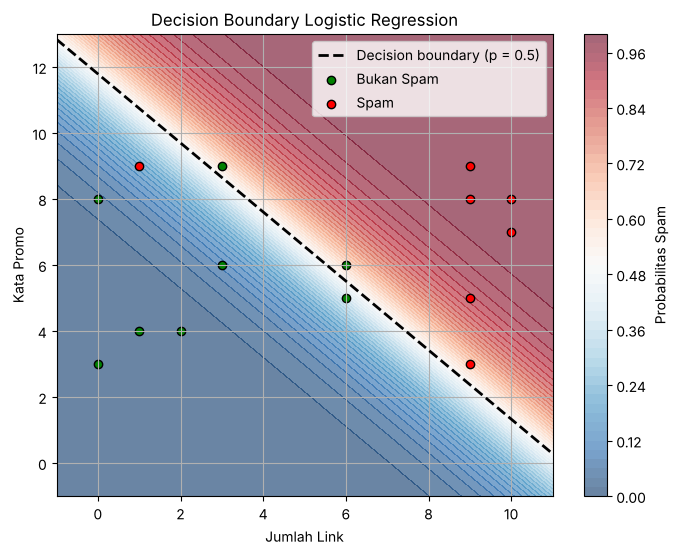

In [12]:
# Jawaban B4
# Decision boundary: b + m1*x1 + m2*x2 = 0  ->  x2 = -(b + m1*x1) / m2   (saat probabilitas = 0.5)
b0, m1, m2 = model_b.b, model_b.w[0], model_b.w[1]
print(f"Persamaan boundary : {b0:.4f} + {m1:.4f}*JumlahLink + {m2:.4f}*KataPromo = 0")
print(f"Bentuk eksplisit   : KataPromo = {-b0/m2:.4f} - {m1/m2:.4f} * JumlahLink")

plt.figure(figsize=(8, 6))
x_min, x_max = X_email[:, 0].min() - 1, X_email[:, 0].max() + 1
y_min, y_max = X_email[:, 1].min() - 1, X_email[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200), np.linspace(y_min, y_max, 200))
grid = np.c_[xx.ravel(), yy.ravel()]
probs = model_b.predict_proba(grid).reshape(xx.shape)

# Background probabilitas (merah = probabilitas spam tinggi)
plt.contourf(xx, yy, probs, levels=50, cmap="RdBu_r", alpha=0.6)
plt.colorbar(label='Probabilitas Spam')

# Garis decision boundary (p = 0.5)
x_line_b = np.linspace(x_min, x_max, 100)
y_line_b = -(b0 + m1 * x_line_b) / m2
plt.plot(x_line_b, y_line_b, 'k--', linewidth=2, label='Decision boundary (p = 0.5)')

# Data testing
plt.scatter(X_test_b[y_test_b==0][:, 0], X_test_b[y_test_b==0][:, 1], color='green', label='Bukan Spam', edgecolor='k')
plt.scatter(X_test_b[y_test_b==1][:, 0], X_test_b[y_test_b==1][:, 1], color='red', label='Spam', edgecolor='k')
plt.xlim(x_min, x_max)
plt.ylim(y_min, y_max)
plt.title('Decision Boundary Logistic Regression')
plt.xlabel('Jumlah Link')
plt.ylabel('Kata Promo')
plt.legend()
plt.grid(True)
plt.show()

**Jawaban B4:**
Decision boundary berada pada titik di mana probabilitas spam tepat 0.5, yaitu saat $b + m_1 x_1 + m_2 x_2 = 0$:

$$-10.4244 + 0.9246 \cdot \text{JumlahLink} + 0.8837 \cdot \text{KataPromo} = 0 \;\Rightarrow\; \text{KataPromo} = 11.7959 - 1.0462 \cdot \text{JumlahLink}$$

Garis ini lurus dan menurun. Email yang berada di atas/kanan garis diprediksi spam (probabilitas > 0.5, area merah), sedangkan di bawah/kiri garis diprediksi bukan spam (area biru). Contohnya, email tanpa link baru dianggap spam bila memiliki lebih dari sekitar 11.8 kata promosi, email dengan 6 link cukup memiliki lebih dari sekitar 5.5 kata promosi, dan email dengan 10 link hanya perlu lebih dari sekitar 1.3 kata promosi. Kemiringan sekitar $-1.05$ berarti satu link kurang lebih setara dengan satu kata promosi, sesuai dengan koefisien keduanya yang hampir sama (0.92 dan 0.88).

Dari 15 titik data testing, 12 berada di sisi yang benar dan 3 berada di sisi yang salah. Ketiganya berada dekat garis atau di daerah bertumpuknya kedua kelas, sesuai dengan hasil pada B3 dan pengamatan di B1.

### Soal B5 – Eksperimen Threshold
Gunakan threshold 0.3, 0.5, dan 0.7 lalu hitung metrik evaluasinya.

In [13]:
# Jawaban B5
thresholds = [0.3, 0.5, 0.7]
proba_test = model_b.predict_proba(X_test_b)

res_b5 = []
for t in thresholds:
    preds = (proba_test >= t).astype(int)
    _, cm_t, prec_t, rec_t, _ = classification_metrics(y_test_b, preds)
    res_b5.append({
        'Threshold': t,
        'Confusion Matrix': f"[{cm_t[0,0]}, {cm_t[0,1]}, {cm_t[1,0]}, {cm_t[1,1]}]",
        'Precision': round(prec_t, 4),
        'Recall': round(rec_t, 4)
    })

print(pd.DataFrame(res_b5).to_string(index=False))

 Threshold Confusion Matrix  Precision  Recall
       0.3     [5, 3, 1, 6]     0.6667  0.8571
       0.5     [6, 2, 1, 6]     0.7500  0.8571
       0.7     [8, 0, 2, 5]     1.0000  0.7143


**Jawaban B5:**

| Threshold | Confusion Matrix [TN, FP, FN, TP] | Precision | Recall |
|---|---|---|---|
| 0.3 | [5, 3, 1, 6] | 0.6667 | 0.8571 |
| 0.5 | [6, 2, 1, 6] | 0.7500 | 0.8571 |
| 0.7 | [8, 0, 2, 5] | 1.0000 | 0.7143 |

Semakin tinggi threshold, model semakin "ketat" dalam menandai spam. Pada threshold 0.3, jumlah email biasa yang salah ditandai spam (FP) naik menjadi 3, sehingga precision turun ke 0.6667, sedangkan recall tetap 0.8571 karena email spam yang lolos (probabilitas 0.176) memang terlalu rendah untuk tertangkap. Pada threshold 0.7, tidak ada email biasa yang salah ditandai (FP = 0, precision 1.0000), tetapi email spam yang lolos bertambah menjadi 2 (FN = 2) sehingga recall turun ke 0.7143. Inilah trade-off antara precision dan recall.

Pada filter spam, salah menandai email penting sebagai spam (FP) biasanya lebih merugikan daripada membiarkan sebagian spam masuk, sehingga threshold yang lebih tinggi seperti 0.7 bisa menjadi pilihan yang lebih aman, dengan konsekuensi 2 dari 7 spam lolos ke inbox. Threshold 0.5 adalah kompromi yang seimbang (F1 = 0.80). Karena data testing hanya 15 email, kesimpulan ini bersifat indikatif.

### Soal B6 – Prediksi Email Baru
Prediksi kelas dan probabilitas spam untuk email baru (E1, E2, E3, E4).

In [14]:
# Jawaban B6
new_emails = pd.DataFrame({
    'Email': ['E1', 'E2', 'E3', 'E4'],
    'JumlahLink': [1, 5, 9, 2],
    'KataPromo': [2, 6, 10, 11]
})

features = new_emails[['JumlahLink', 'KataPromo']].values
probas = model_b.predict_proba(features)
preds_selected = (probas >= 0.5).astype(int)

new_emails['Probabilitas Spam'] = np.round(probas, 4)
new_emails['Prediksi'] = ['Spam' if p == 1 else 'Bukan Spam' for p in preds_selected]

print(new_emails.to_string(index=False))

Email  JumlahLink  KataPromo  Probabilitas Spam   Prediksi
   E1           1          2             0.0004 Bukan Spam
   E2           5          6             0.3777 Bukan Spam
   E3           9         10             0.9988       Spam
   E4           2         11             0.7587       Spam


**Jawaban B6:**

| Email | JumlahLink | KataPromo | Probabilitas Spam | Prediksi |
|---|---|---|---|---|
| E1 | 1 | 2 | 0.0004 | Bukan Spam |
| E2 | 5 | 6 | 0.3777 | Bukan Spam |
| E3 | 9 | 10 | 0.9988 | Spam |
| E4 | 2 | 11 | 0.7587 | Spam |

- **E1** sangat jelas bukan spam (probabilitas 0.0004), karena link dan kata promosinya sedikit.
- **E2** diprediksi bukan spam, tetapi probabilitasnya 0.3777 sudah dekat dengan batas 0.5 (posisinya hanya sedikit di bawah garis decision boundary). Email ini termasuk ambigu, dan akan dianggap spam jika threshold diturunkan ke 0.3 seperti pada B5.
- **E3** hampir pasti spam (0.9988) karena link dan kata promosinya sama-sama banyak.
- **E4** diprediksi spam (0.7587) meskipun hanya punya 2 link, karena 11 kata promosi sudah cukup mendorong nilai $z = -10.4244 + 0.9246 \cdot 2 + 0.8837 \cdot 11 = 1.1458$ melewati 0, sehingga probabilitasnya di atas 0.5.

---
# Bagian C – Pemahaman Konsep (15%)

**Jawaban C1:**
Logistic Regression termasuk algoritma klasifikasi karena output-nya dipetakan ke dalam kategori diskrit (misal 0 atau 1) menggunakan fungsi sigmoid yang mengubah nilai kontinu menjadi rentang probabilitas antara 0 dan 1.

**Jawaban C2:**
Normal equation menghitung parameter secara langsung menggunakan invers matriks tanpa iterasi, cocok untuk dataset kecil. Gradient descent menggunakan iterasi untuk memperbarui parameter secara bertahap, sehingga lebih efisien untuk dataset berukuran besar.

**Jawaban C3:**
Model dievaluasi pada data testing untuk menguji performanya pada data baru yang belum pernah dilihat sebelumnya. Overfitting terjadi ketika model terlalu menghafal data training sehingga gagal melakukan generalisasi pada data testing. Pada notebook ini, $R^2$ training 0.9548 dan $R^2$ testing 0.9029 (selisih sekitar 0.05), sehingga model tidak mengalami overfitting yang serius.

**Jawaban C4:**
Linear Regression menggunakan MSE karena output-nya berupa nilai kontinu. Logistic Regression menggunakan log loss (binary cross-entropy) agar penalaran penalti error sesuai dengan fungsi probabilitas non-linier dari fungsi sigmoid.

**Jawaban C5:**
Hasil angka bisa berbeda karena adanya perbedaan pada inisialisasi random state saat membagi data training dan testing (train-test split), yang menghasilkan subset data pelatihan yang berbeda.

---
# Bonus (+5) – Perbandingan dengan scikit-learn

In [15]:
# Jawaban Bonus
from sklearn.linear_model import LinearRegression, LogisticRegression as SklearnLogReg

# Linear Regression sklearn
sk_lin = LinearRegression()
sk_lin.fit(X_train_a, y_train_a)
print(f"Sklearn Linear Reg - Intercept: {sk_lin.intercept_:.4f}, Coef: {sk_lin.coef_[0]:.4f}")

# Logistic Regression sklearn
sk_log = SklearnLogReg()
sk_log.fit(X_train_b, y_train_b)
print(f"Sklearn Logistic Reg - Intercept: {sk_log.intercept_[0]:.4f}, Coefs: {sk_log.coef_[0]}")

# Perbandingan metrik pada data testing (manual vs scikit-learn)
print(f"R2 test Linear Reg   -> manual: {r2_score(y_test_a, y_pred_test_a):.4f} | sklearn: {sk_lin.score(X_test_a, y_test_a):.4f}")
print(f"Akurasi test Logistic -> manual: {acc:.4f} | sklearn: {sk_log.score(X_test_b, y_test_b):.4f}")
print(f"Prediksi test Logistic sama persis: {np.mean(sk_log.predict(X_test_b) == model_b.predict(X_test_b)) * 100:.0f}%")

Sklearn Linear Reg - Intercept: 29.1879, Coef: 8.9897
Sklearn Logistic Reg - Intercept: -9.6239, Coefs: [0.84079216 0.82075378]
R2 test Linear Reg   -> manual: 0.9029 | sklearn: 0.9029
Akurasi test Logistic -> manual: 0.8000 | sklearn: 0.8000
Prediksi test Logistic sama persis: 100%


**Jawaban Bonus (analisis):**

| Model | Parameter manual | Parameter scikit-learn |
|---|---|---|
| Linear Regression | $b = 29.1879$, $m = 8.9897$ | $b = 29.1879$, $m = 8.9897$ |
| Logistic Regression | $b = -10.4244$, $m_1 = 0.9246$, $m_2 = 0.8837$ | $b = -9.6239$, $m_1 = 0.8408$, $m_2 = 0.8208$ |

- **Linear Regression:** hasilnya identik sampai 4 angka desimal, begitu pula $R^2$ pada data testing (0.9029 untuk keduanya). Ini wajar karena scikit-learn juga menghitung solusi kuadrat terkecil yang sama dengan normal equation, dan gradient descent dengan learning rate 0.02 pada A5 juga menuju solusi yang sama.
- **Logistic Regression:** koefisien scikit-learn lebih kecil daripada implementasi manual. Penyebabnya, scikit-learn secara default menerapkan regularisasi L2 (`C=1.0`) yang menekan besar koefisien, sedangkan implementasi manual memakai gradient descent murni tanpa regularisasi. Meskipun parameternya berbeda, akurasi pada data testing sama (0.8000) dan seluruh prediksi pada 15 data testing identik, sehingga perbedaan ini praktis tidak berpengaruh pada hasil klasifikasi dengan data seperti ini.